In [1]:
import os
import numpy as np
import cv2
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.applications import EfficientNetB0 as EfficientNet
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from skimage.feature import hog
from skimage import color
import random

In [2]:
train_dir = 'D:\\Egyptian money detection\\Egyptian new currency\\dataset\\train'
val_dir = 'D:\\Egyptian money detection\\Egyptian new currency\\dataset\\valid'
test_dir = 'D:\\Egyptian money detection\\Egyptian new currency\\dataset\\test'

class_names = sorted(os.listdir(train_dir))
print("Classes:", class_names)

Classes: ['1', '10', '10 (new)', '100', '20', '20 (new)', '200', '5', '50']


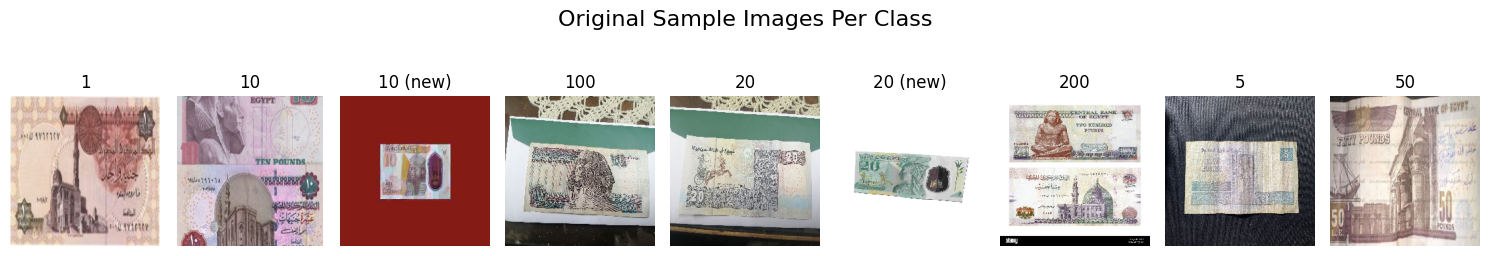

In [21]:
# Plot sample original images per class
def show_original_class_examples(directory, target_size=(224, 224)):
    classes = sorted(os.listdir(directory))
    plt.figure(figsize=(15, 3))
    for idx, label in enumerate(classes):
        class_path = os.path.join(directory, label)
        img_path = os.path.join(class_path, os.listdir(class_path)[0])
        img = cv2.imread(img_path)
        img = cv2.resize(img, target_size)
        plt.subplot(1, len(classes), idx + 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(label)
        plt.axis('off')
    plt.suptitle("Original Sample Images Per Class", fontsize=16)
    plt.tight_layout()
    plt.show()

show_original_class_examples(train_dir)

In [3]:
# Preprocessing filters
def apply_sift(image, max_keypoints=100):
    sift = cv2.SIFT_create(nfeatures=max_keypoints)
    keypoints, descriptors = sift.detectAndCompute(image, None)
    sift_image = np.zeros_like(image)
    sift_image = cv2.drawKeypoints(image, keypoints, sift_image, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    return cv2.cvtColor(sift_image, cv2.COLOR_BGR2RGB)

In [4]:
def apply_hog(image):
    gray = color.rgb2gray(image)
    _, hog_image = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        visualize=True
    )
    hog_image = (hog_image * 255).astype(np.uint8)
    return cv2.cvtColor(hog_image, cv2.COLOR_GRAY2RGB)

In [5]:
def apply_combined_sift_hog(image):
    sift_img = apply_sift(image)
    hog_img = apply_hog(image)
    return cv2.addWeighted(sift_img, 0.5, hog_img, 0.5, 0)

In [6]:
# Data loader
def load_images_from_directory(directory, preprocess_fn, target_size=(224, 224)):
    X, y = [], []
    classes = sorted(os.listdir(directory))
    for label in classes:
        class_path = os.path.join(directory, label)
        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)
            img = cv2.imread(img_path)
            if img is None:
                continue
            img = cv2.resize(img, target_size)
            img = preprocess_fn(img)
            X.append(img)
            y.append(label)
    return np.array(X), np.array(y)

In [7]:
# Show sample images
def show_sample_images(X, y, title, class_labels):
    plt.figure(figsize=(12, 4))
    indices = random.sample(range(len(X)), 5)
    for i, idx in enumerate(indices):
        plt.subplot(1, 5, i + 1)
        plt.imshow(X[idx])
        label_index = np.argmax(y[idx]) if y.ndim == 2 else y[idx]
        plt.title(class_labels[label_index])
        plt.axis('off')
    plt.suptitle(f"Sample Images After {title} Preprocessing", fontsize=16)
    plt.tight_layout()
    plt.show()

In [8]:
# Prepare data
def prepare_data(train_dir, val_dir, test_dir, preprocess_fn):
    X_train, y_train = load_images_from_directory(train_dir, preprocess_fn)
    X_val, y_val = load_images_from_directory(val_dir, preprocess_fn)
    X_test, y_test = load_images_from_directory(test_dir, preprocess_fn)

    le = LabelEncoder()
    y_train_enc = to_categorical(le.fit_transform(y_train))
    y_val_enc = to_categorical(le.transform(y_val))
    y_test_enc = to_categorical(le.transform(y_test))

    X_train = X_train.astype('float32') / 255.0
    X_val = X_val.astype('float32') / 255.0
    X_test = X_test.astype('float32') / 255.0

    return X_train, y_train_enc, X_val, y_val_enc, X_test, y_test_enc, le

In [9]:
# Model builder
def build_model(input_shape, num_classes):
    base = EfficientNet(include_top=False, weights='imagenet', input_shape=input_shape)
    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation='relu')(x)
    out = Dense(num_classes, activation='softmax')(x)
    model = Model(inputs=base.input, outputs=out)
    model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

In [10]:
# Training pipeline
def train_pipeline(name, preprocess_fn):
    print(f"\n🔧 Training model with {name} preprocessing...")
    X_train, y_train, X_val, y_val, X_test, y_test, le = prepare_data(train_dir, val_dir, test_dir, preprocess_fn)

    show_sample_images(X_train, y_train, name, le.classes_)

    model = build_model(X_train.shape[1:], y_train.shape[1])
    es = EarlyStopping(patience=5, restore_best_weights=True)

    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=8, callbacks=[es])
    loss, acc = model.evaluate(X_test, y_test)

    print(f"✅ {name} Test Accuracy: {acc:.4f}")
    return model, acc, (X_test, y_test, le)

Run Models



🔧 Training model with SIFT preprocessing...


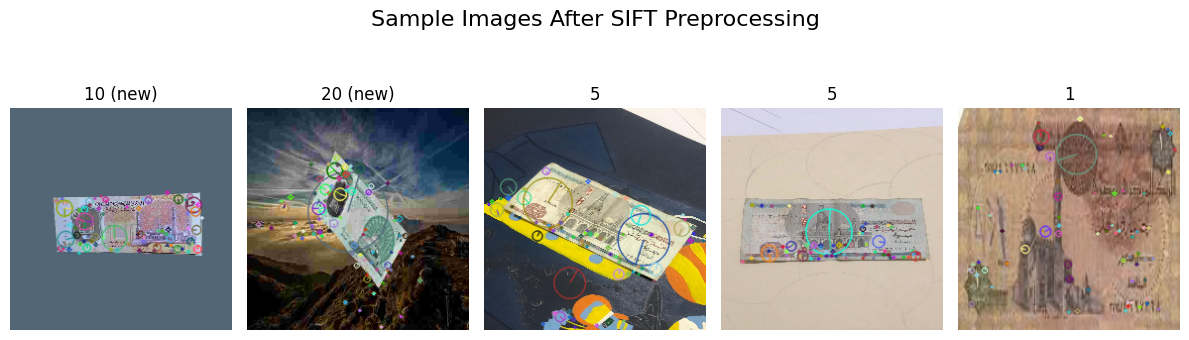

Epoch 1/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 193s 517ms/step - accuracy: 0.3387 - loss: 1.8731 - val_accuracy: 0.0658 - val_loss: 2.2330
Epoch 2/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 180s 546ms/step - accuracy: 0.8676 - loss: 0.4645 - val_accuracy: 0.7079 - val_loss: 0.9010
Epoch 3/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 179s 542ms/step - accuracy: 0.9447 - loss: 0.1972 - val_accuracy: 0.9711 - val_loss: 0.1007
Epoch 4/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 177s 536ms/step - accuracy: 0.9600 - loss: 0.1314 - val_accuracy: 0.9711 - val_loss: 0.0835
Epoch 5/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 173s 525ms/step - accuracy: 0.9683 - loss: 0.0997 - val_accuracy: 0.9803 - val_loss: 0.0531
Epoch 6/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 170s 515ms/step - accuracy: 0.9806 - loss: 0.0646 - val_accuracy: 0.9842 - val_loss: 0.0518
Epoch 7/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 178s 539ms/step - accuracy: 0.9806 - loss: 0.0606 - val_accuracy: 0.9829 - val_loss: 0.0535
Epoch 8/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 178s 540ms/step - accuracy: 0.9880 -

In [11]:
model_sift, acc_sift, test_sift = train_pipeline("SIFT", apply_sift)


🔧 Training model with HOG preprocessing...


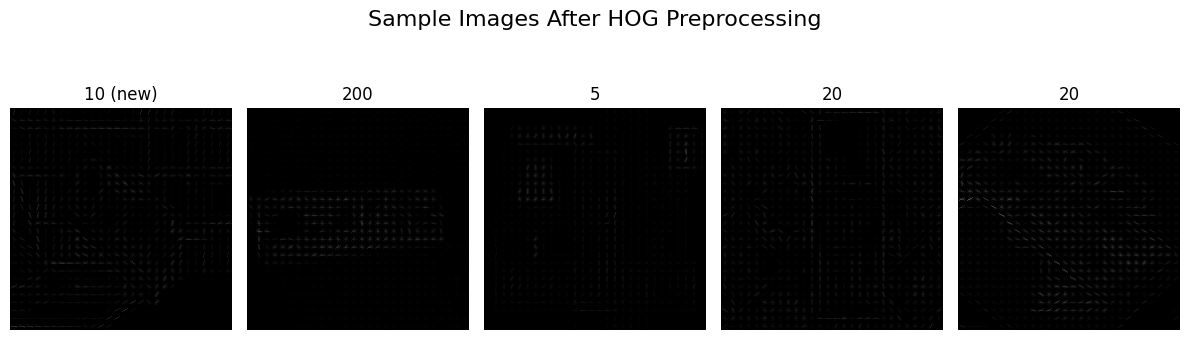

Epoch 1/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 295s 818ms/step - accuracy: 0.2405 - loss: 2.0077 - val_accuracy: 0.1039 - val_loss: 2.1941
Epoch 2/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 258s 783ms/step - accuracy: 0.6841 - loss: 0.9725 - val_accuracy: 0.1513 - val_loss: 2.1870
Epoch 3/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 228s 692ms/step - accuracy: 0.8623 - loss: 0.4576 - val_accuracy: 0.8500 - val_loss: 0.4780
Epoch 4/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 248s 753ms/step - accuracy: 0.9255 - loss: 0.2535 - val_accuracy: 0.9224 - val_loss: 0.3070
Epoch 5/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 271s 822ms/step - accuracy: 0.9377 - loss: 0.2056 - val_accuracy: 0.8724 - val_loss: 0.4157
Epoch 6/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 275s 834ms/step - accuracy: 0.9600 - loss: 0.1414 - val_accuracy: 0.9224 - val_loss: 0.2541
Epoch 7/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 254s 771ms/step - accuracy: 0.9708 - loss: 0.1032 - val_accuracy: 0.9276 - val_loss: 0.2341
Epoch 8/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 248s 752ms/step - accuracy: 0.9791 -

In [12]:
model_hog, acc_hog, test_hog = train_pipeline("HOG", apply_hog)


🔧 Training model with Combined SIFT+HOG preprocessing...


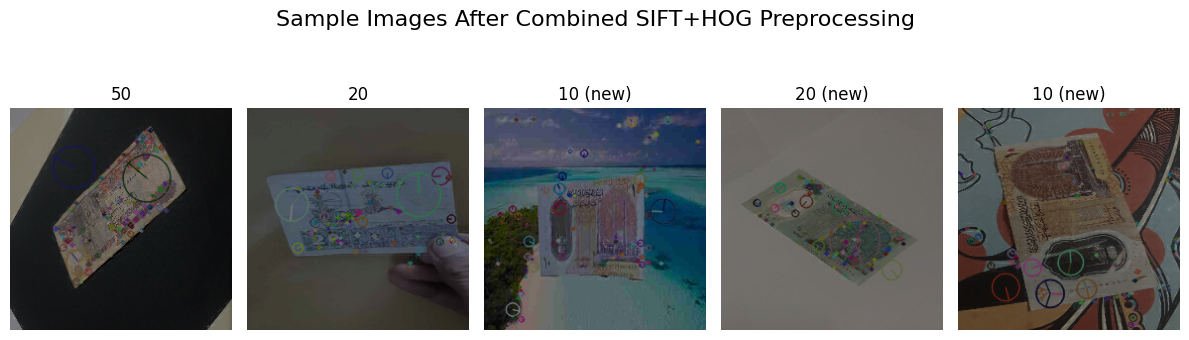

Epoch 1/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 272s 737ms/step - accuracy: 0.3268 - loss: 1.8628 - val_accuracy: 0.0697 - val_loss: 2.2024
Epoch 2/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 232s 702ms/step - accuracy: 0.8930 - loss: 0.4096 - val_accuracy: 0.6289 - val_loss: 1.1349
Epoch 3/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 245s 743ms/step - accuracy: 0.9448 - loss: 0.1880 - val_accuracy: 0.9697 - val_loss: 0.1157
Epoch 4/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 275s 835ms/step - accuracy: 0.9704 - loss: 0.1016 - val_accuracy: 0.9776 - val_loss: 0.0770
Epoch 5/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 279s 845ms/step - accuracy: 0.9753 - loss: 0.0885 - val_accuracy: 0.9816 - val_loss: 0.0693
Epoch 6/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 276s 837ms/step - accuracy: 0.9821 - loss: 0.0636 - val_accuracy: 0.9842 - val_loss: 0.0594
Epoch 7/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 278s 842ms/step - accuracy: 0.9861 - loss: 0.0563 - val_accuracy: 0.9829 - val_loss: 0.0642
Epoch 8/20
330/330 ━━━━━━━━━━━━━━━━━━━━ 277s 839ms/step - accuracy: 0.9892 -

In [13]:
model_combined, acc_combined, test_combined = train_pipeline("Combined SIFT+HOG", apply_combined_sift_hog)

In [14]:
# Compare results
print("\n🔍 Final Accuracy Comparison:")
print(f"SIFT Accuracy:     {acc_sift:.4f}")
print(f"HOG Accuracy:      {acc_hog:.4f}")
print(f"Combined Accuracy: {acc_combined:.4f}")


🔍 Final Accuracy Comparison:
SIFT Accuracy:     0.9931
HOG Accuracy:      0.9552
Combined Accuracy: 0.9931


In [ ]:
#Save models
model_sift.save("sift_model.h5")
model_hog.save("hog_model.h5")
model_combined.save("combined_sift_hog_model.h5")

In [17]:
# Visualize predictions on random test images
def show_model_predictions(models, preprocess_fns, model_names, test_dir, le):
    class_labels = le.classes_
    all_files = []
    for cls in os.listdir(test_dir):
        for fname in os.listdir(os.path.join(test_dir, cls)):
            all_files.append(os.path.join(test_dir, cls, fname))

    selected = random.sample(all_files, 5)

    for i, img_path in enumerate(selected):
        orig = cv2.imread(img_path)
        img_resized = cv2.resize(orig, (224, 224))

        plt.figure(figsize=(12, 2))
        plt.subplot(1, len(models)+1, 1)
        plt.imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
        plt.title("Original")
        plt.axis('off')

        for j, (model, fn, name) in enumerate(zip(models, preprocess_fns, model_names)):
            processed = fn(img_resized)
            input_img = processed.astype('float32') / 255.0
            input_img = np.expand_dims(input_img, axis=0)
            pred = model.predict(input_img)
            label = class_labels[np.argmax(pred)]

            plt.subplot(1, len(models)+1, j + 2)
            plt.imshow(processed)
            plt.title(f"{name}\n{label}")
            plt.axis('off')

        plt.tight_layout()
        plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


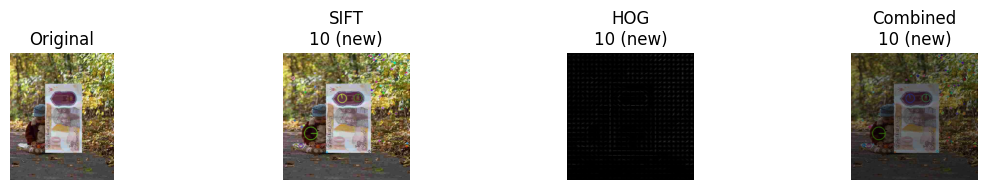

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


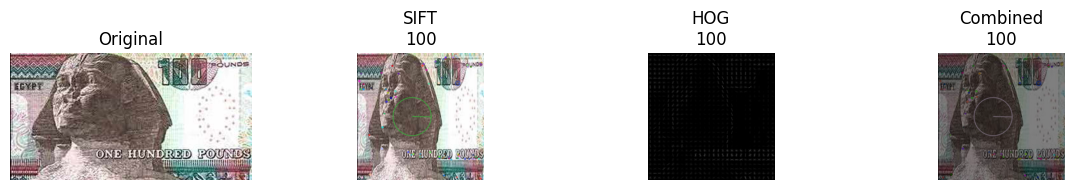

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


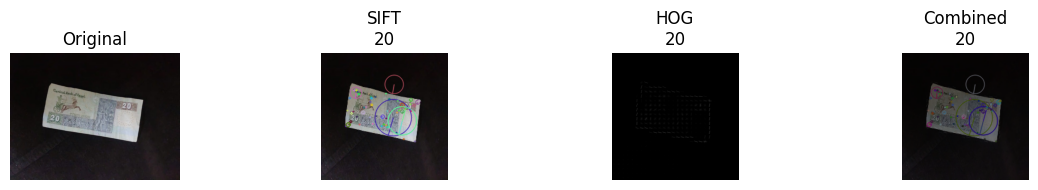

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


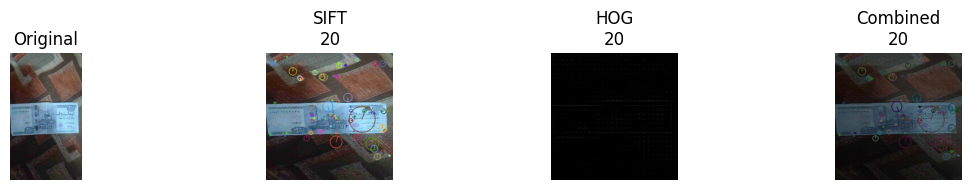

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


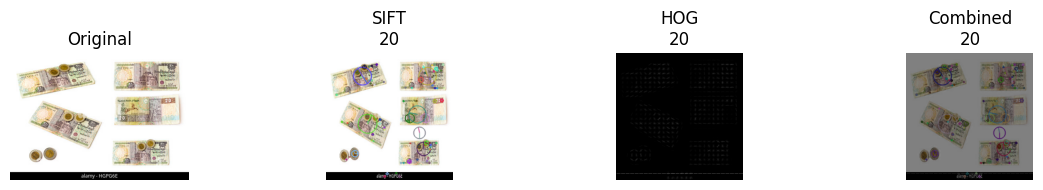

In [18]:
# Show predictions
show_model_predictions(
    models=[model_sift, model_hog, model_combined],
    preprocess_fns=[apply_sift, apply_hog, apply_combined_sift_hog],
    model_names=["SIFT", "HOG", "Combined"],
    test_dir=test_dir,
    le=test_combined[2]  # LabelEncoder from last run
)


In [ ]:
def predict_on_custom_image(image_path, models, preprocess_fns, model_names, label_encoder):
    img = cv2.imread(image_path)
    if img is None:
        print("Error: Image not found.")
        return
    img_resized = cv2.resize(img, (224, 224))

    plt.figure(figsize=(12, 2))
    plt.subplot(1, len(models)+1, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis('off')

    for i, (model, preprocess_fn, name) in enumerate(zip(models, preprocess_fns, model_names)):
        processed = preprocess_fn(img_resized)
        input_img = processed.astype('float32') / 255.0
        input_img = np.expand_dims(input_img, axis=0)
        pred = model.predict(input_img)
        pred_label = label_encoder.classes_[np.argmax(pred)]

        plt.subplot(1, len(models)+1, i + 2)
        plt.imshow(processed)
        plt.title(f"{name}\n{pred_label}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


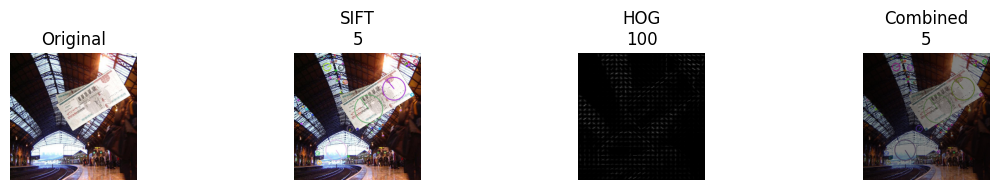

In [25]:
predict_on_custom_image(
    image_path="D:\\Egyptian money detection\\Egyptian currency\\3rd\\199904857.jpg",
    models=[model_sift, model_hog, model_combined],
    preprocess_fns=[apply_sift, apply_hog, apply_combined_sift_hog],
    model_names=["SIFT", "HOG", "Combined"],
    label_encoder=test_combined[2]
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


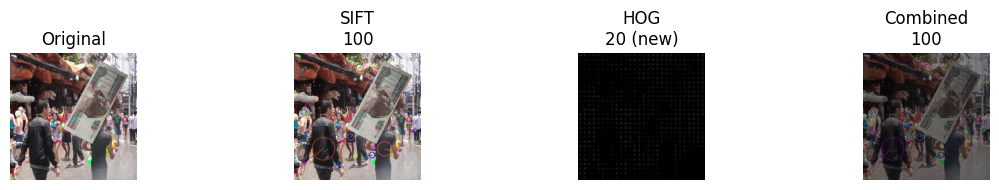

In [26]:
predict_on_custom_image(
    image_path="D:\\Egyptian money detection\\Egyptian currency\\10th\\905318149.jpg",
    models=[model_sift, model_hog, model_combined],
    preprocess_fns=[apply_sift, apply_hog, apply_combined_sift_hog],
    model_names=["SIFT", "HOG", "Combined"],
    label_encoder=test_combined[2]
)

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion_matrix(model, X_test, y_test, label_encoder, title):
    y_pred = model.predict(X_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_test, axis=1)

    cm = confusion_matrix(y_true_classes, y_pred_classes)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
    plt.title(f"Confusion Matrix - {title}")
    plt.show()


10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 269ms/step


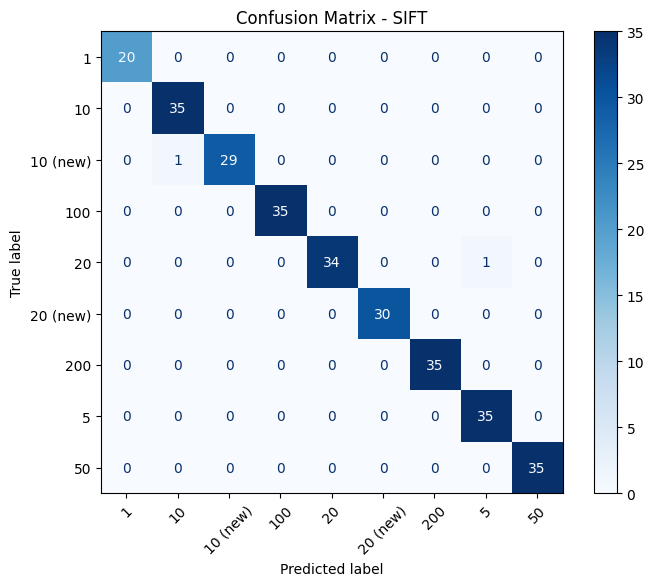

In [29]:
plot_confusion_matrix(model_sift, test_sift[0], test_sift[1], test_sift[2], "SIFT")



10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step


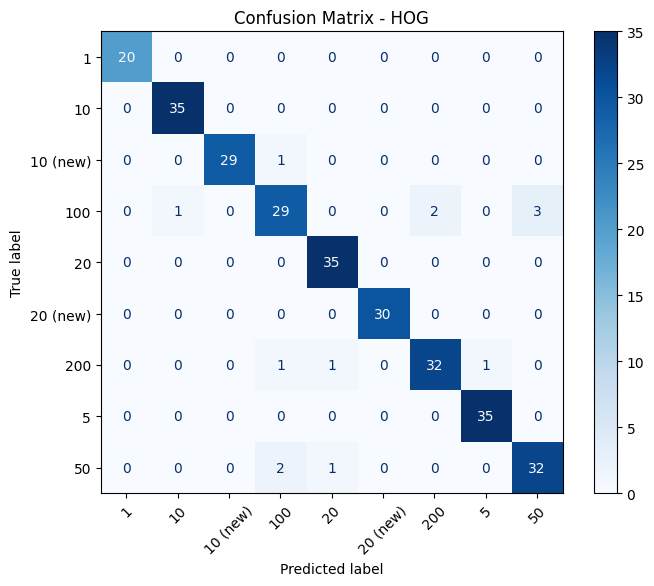

In [30]:
plot_confusion_matrix(model_hog, test_hog[0], test_hog[1], test_hog[2], "HOG")


10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 280ms/step


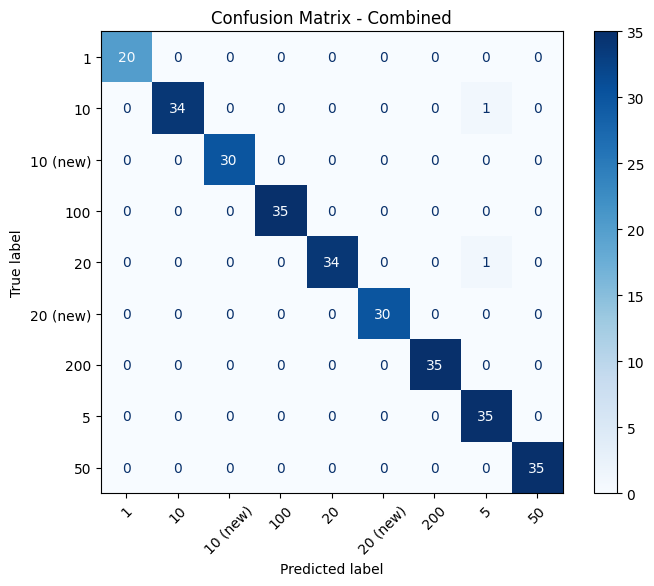

In [31]:
plot_confusion_matrix(model_combined, test_combined[0], test_combined[1], test_combined[2], "Combined")

In [32]:
from sklearn.metrics import classification_report

def evaluate_model_metrics(model, X_test, y_test, label_encoder, title):
    y_pred = model.predict(X_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_test, axis=1)

    print(f"\n📊 Classification Report for {title}:")
    print(classification_report(y_true_classes, y_pred_classes, target_names=label_encoder.classes_))


In [33]:
evaluate_model_metrics(model_sift, test_sift[0], test_sift[1], test_sift[2], "SIFT")



10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 274ms/step

📊 Classification Report for SIFT:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        20
          10       0.97      1.00      0.99        35
    10 (new)       1.00      0.97      0.98        30
         100       1.00      1.00      1.00        35
          20       1.00      0.97      0.99        35
    20 (new)       1.00      1.00      1.00        30
         200       1.00      1.00      1.00        35
           5       0.97      1.00      0.99        35
          50       1.00      1.00      1.00        35

    accuracy                           0.99       290
   macro avg       0.99      0.99      0.99       290
weighted avg       0.99      0.99      0.99       290



In [34]:
evaluate_model_metrics(model_hog, test_hog[0], test_hog[1], test_hog[2], "HOG")


10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 278ms/step

📊 Classification Report for HOG:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        20
          10       0.97      1.00      0.99        35
    10 (new)       1.00      0.97      0.98        30
         100       0.88      0.83      0.85        35
          20       0.95      1.00      0.97        35
    20 (new)       1.00      1.00      1.00        30
         200       0.94      0.91      0.93        35
           5       0.97      1.00      0.99        35
          50       0.91      0.91      0.91        35

    accuracy                           0.96       290
   macro avg       0.96      0.96      0.96       290
weighted avg       0.95      0.96      0.95       290



In [35]:
evaluate_model_metrics(model_combined, test_combined[0], test_combined[1], test_combined[2], "Combined")

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 264ms/step

📊 Classification Report for Combined:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        20
          10       1.00      0.97      0.99        35
    10 (new)       1.00      1.00      1.00        30
         100       1.00      1.00      1.00        35
          20       1.00      0.97      0.99        35
    20 (new)       1.00      1.00      1.00        30
         200       1.00      1.00      1.00        35
           5       0.95      1.00      0.97        35
          50       1.00      1.00      1.00        35

    accuracy                           0.99       290
   macro avg       0.99      0.99      0.99       290
weighted avg       0.99      0.99      0.99       290

